# Pronóstico multivariado con una RNN

Abordajes diarios en Chicago (CTA). El cuaderno predice el tren del día siguiente a partir de tren, bus y el tipo de día. Tiene seis partes:

1. Carga de datos
2. Series multivariadas
3. Series a tensores
4. Dataset con ventanas y DataLoaders
5. Entrenamiento de una RNN profunda
6. Pronóstico en el conjunto de prueba

## 1. Carga de datos

Leemos el CSV de abordajes diarios, acortamos los nombres de las columnas y usamos la fecha como índice. Quitamos `total` (es la suma de bus y tren) y las filas duplicadas.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from torch import nn
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

In [2]:
path = Path('CTA_-_Ridership_-_Daily_Boarding_Totals.csv')
df = pd.read_csv(path, parse_dates=["service_date"], thousands=",")
df.columns = ["date", "day_type", "bus", "rail", "total"]  # nombres cortos
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis=1)  # total = bus + tren
df = df.drop_duplicates()  # meses duplicados: 2011-10 y 2014-07

## 2. Series multivariadas

La entrada usa tren y bus, en millones de abordajes, y el tipo de día siguiente en one-hot. Ese tipo se conoce de antemano.

In [3]:
df_mulvar = df[["rail", "bus"]] / 1e6  # use both rail & bus series as input
df_mulvar["next_day_type"] = df["day_type"].shift(-1)  # we know tomorrow's type
df_mulvar = pd.get_dummies(df_mulvar, dtype=float)  # one-hot encode day type

## 3. Series a tensores

Cada fila pasa a un tensor `float32` con las cinco columnas. Entrenamiento: 2016 a 2018. Validación: enero a mayo de 2019. Prueba: desde junio de 2019.

In [4]:
train = torch.tensor(df_mulvar["2016-01-01":"2018-12-31"].values, dtype=torch.float32)
valid = torch.tensor(df_mulvar["2019-01-01":"2019-05-31"].values, dtype=torch.float32)    
test = torch.tensor(df_mulvar["2019-06-01":].values, dtype=torch.float32)

## 4. Dataset con ventanas y DataLoaders

`TimeSeriesDataset` arma pares de una ventana de 56 días y el día siguiente. `TimeSeriesDataset_multivariate` deja como objetivo solo la primera columna, el abordaje de tren. Los DataLoaders entregan esos pares en lotes de 32. El de entrenamiento se baraja; la validación conserva el orden.

In [5]:
class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, series, window_length):
        self.series = series
        self.window_length = window_length

    def __len__(self):
        return len(self.series) - self.window_length

    def __getitem__(self, idx):
        if idx >= len(self):
            raise IndexError("dataset index out of range")
        end = idx + self.window_length  # 1st index after window
        window = self.series[idx : end]
        target = self.series[end]
        return window, target

In [6]:
class TimeSeriesDataset_multivariate(TimeSeriesDataset):
    def __getitem__(self, idx):
        window, target = super().__getitem__(idx)
        target = target[:1]
        return window, target

In [7]:
train_set = TimeSeriesDataset_multivariate(train, 56)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True)
valid_set = TimeSeriesDataset_multivariate(valid, 56)
valid_loader = torch.utils.data.DataLoader(valid_set, batch_size=32, shuffle=False)

## 5. Entrenamiento de una RNN profunda

Tres capas recurrentes (`num_layers=3`) leen la ventana de cinco variables. La predicción sale del último paso y estima el abordaje de tren del día siguiente. Se entrena con pérdida de Huber, Adam (`lr=0.001`) y 200 épocas. Cada 50 épocas se mide el MAPE en validación.

In [8]:
class SimpleRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, num_layers=3)
        self.out = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        output, hidden = self.rnn(x)
        return self.out(output[:, -1])

model = SimpleRNN(input_size=5, hidden_size=32, output_size=1).to(device)

In [9]:
import torch.nn as nn
import torchmetrics

loss_fn = nn.HuberLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
MAPE = torchmetrics.MeanAbsolutePercentageError().to(device)
n_epochs = 500

In [10]:
for epoch in range(n_epochs):
    model.train()
    total_loss = 0
    MAPE.reset()
    for batch in train_loader:
        window, target = batch
        window, target = window.to(device), target.to(device)
        pred = model(window)
        loss = loss_fn(pred, target)
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    if epoch % 50 == 0:
        model.eval()
        with torch.no_grad():
            for window, target in valid_loader:
                window = window.to(device)
                target = target.to(device)
                pred = model(window)
                MAPE.update(pred, target)
        mean_loss = total_loss / len(train_loader)
        mape = MAPE.compute()
        print(f"Epoch {epoch+1}/{n_epochs}, Loss: {mean_loss:.4f}, MAPE: {mape:.4f}")

Epoch 1/500, Loss: 0.0561, MAPE: 0.2969
Epoch 51/500, Loss: 0.0011, MAPE: 0.0533
Epoch 101/500, Loss: 0.0010, MAPE: 0.0581
Epoch 151/500, Loss: 0.0010, MAPE: 0.0565
Epoch 201/500, Loss: 0.0008, MAPE: 0.0553
Epoch 251/500, Loss: 0.0009, MAPE: 0.0728
Epoch 301/500, Loss: 0.0007, MAPE: 0.0489
Epoch 351/500, Loss: 0.0007, MAPE: 0.0492
Epoch 401/500, Loss: 0.0005, MAPE: 0.0480
Epoch 451/500, Loss: 0.0004, MAPE: 0.0492


## 6. Pronóstico en el conjunto de prueba

La primera ventana de prueba, 56 días desde junio de 2019, produce el pronóstico del día siguiente. La figura muestra esa ventana de tren, el abordaje real y el pronóstico.

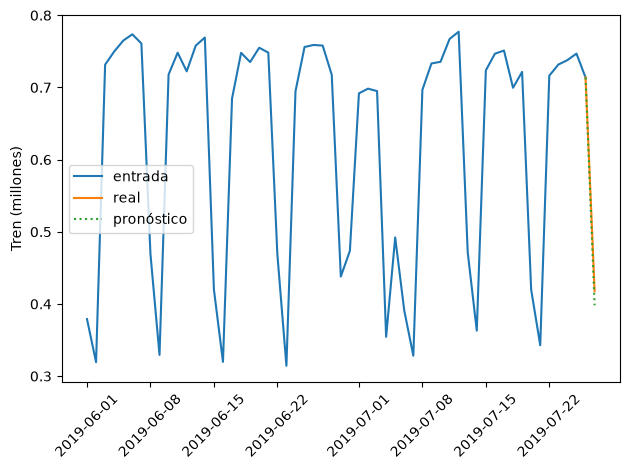

In [11]:
import matplotlib.pyplot as plt

test_set = TimeSeriesDataset_multivariate(test, 56)
window, target = test_set[0]
model.eval()
with torch.no_grad():
    pred = model(window.unsqueeze(0).to(device)).cpu().squeeze(0)

dates = df_mulvar.loc["2019-06-01":].index[:57]
history = window[:, 0].numpy()
plt.plot(dates[:56], history, label="entrada")
plt.plot(dates[55:], np.r_[history[-1], target.numpy()], label="real")
plt.plot(dates[55:], np.r_[history[-1], pred.numpy()], ":", label="pronóstico")
plt.ylabel("Tren (millones)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()